# BUS 104: Nonlinear Programming (NLP) with Python (`scipy.optimize`)

This notebook contains the step-by-step Python code and visual solutions for all examples and interactive exercises in the **`Nonlinear_Programming.pdf`** lecture slides.

### The 4-Step `scipy.optimize` Framework
1. **Import** the solver tools: `from scipy.optimize import minimize, differential_evolution, LinearConstraint`
2. **Define (`def`)** the objective function using normal Python math *(Golden Rule: Python solvers always **minimize**, so return `-profit` when maximizing!)*
3. **Set Bounds & Constraints** using `bounds = [(low, high), ...]` and `LinearConstraint([coeffs], min_val, max_val)`
4. **Solve & Print** using either:
   - **Hill-Climbing (Reduced Gradient):** `minimize(func, x0=[...], bounds=..., constraints=...)`
   - **Evolutionary Algorithm (Population Search):** `differential_evolution(func, bounds=..., constraints=...)`

## Step 1: Import Libraries
`scipy.optimize` is pre-installed in Google Colab—no `!pip install` is needed!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, differential_evolution, LinearConstraint

plt.rcParams['figure.dpi'] = 110
print("scipy.optimize loaded successfully!")

scipy.optimize loaded successfully!


---
## Part 1 Warm-Up Exercise (Slides 9–9b): Finding a Peak by Testing Numbers vs. Python
**Model B:**
$$\max_{x \ge 0} \; \Pi(x) = 40x - 2x^2$$
First, let's check candidate values $x = 9, 10, 11$ with a simple Python function, and then solve it with `minimize` and `differential_evolution`.

In [2]:
# Define the profit formula
def warmup_profit(x_val):
    return 40 * x_val - 2 * (x_val ** 2)

# 1. Test candidate values x = 9, 10, 11 (No calculus needed!)
for cand in [9, 10, 11]:
    print(f"At x = {cand}: Profit = ${warmup_profit(cand):.2f}")

# 2. Solve with scipy.optimize (Golden Rule: return -profit to maximize!)
def neg_warmup_profit(x):
    x_val = x[0]
    return -(40 * x_val - 2 * (x_val ** 2))

res_warm_grad = minimize(neg_warmup_profit, x0=[1.0], bounds=[(0, 50)])
res_warm_evo  = differential_evolution(neg_warmup_profit, bounds=[(0, 50)], seed=42)

print(f"\n[Hill-Climbing / minimize]          Optimal x* = {res_warm_grad.x[0]:.2f}, Max Profit = ${-res_warm_grad.fun:.2f}")
print(f"[Evolutionary / diff_evolution]     Optimal x* = {res_warm_evo.x[0]:.2f}, Max Profit = ${-res_warm_evo.fun:.2f}")

At x = 9: Profit = $198.00
At x = 10: Profit = $200.00
At x = 11: Profit = $198.00

[Hill-Climbing / minimize]          Optimal x* = 10.00, Max Profit = $200.00
[Evolutionary / diff_evolution]     Optimal x* = 10.00, Max Profit = $200.00


---
## Part 2 Demonstration (Slides 13–19): Multi-Peak Local Trap vs. Evolutionary Algorithm
When a profit landscape has **multiple hills** (e.g., a smaller local hill at $x = 25$ with profit $\$400$ and a taller global mountain at $x = 85$ with profit $\$950$):
- **Hill-Climbing (`minimize`)** from an unlucky starting guess (`x0 = [40]`) walks uphill to the left and gets trapped at the smaller hill ($x = 25$).
- **Testing Multiple Starting Guesses (`x0 = [10], [50], [90]`)** or using **Evolutionary Search (`differential_evolution`)** finds the true global peak ($x^* = 85$).

In [3]:
def multi_peak_profit(x_val):
    return (
        120.0
        + 280.0 * np.exp(-((x_val - 25.0) / 14.0) ** 2)
        + 830.0 * np.exp(-((x_val - 85.0) / 16.0) ** 2)
    )

def neg_multi_peak(x):
    return -multi_peak_profit(x[0])

# 1. Hill-Climbing from a single unlucky start x0 = [40.0]
res_trap = minimize(neg_multi_peak, x0=[40.0], bounds=[(0.0, 100.0)])

# 2. Hill-Climbing from multiple starting guesses x0 in [10, 50, 90]
best_multi = None
for guess in [10.0, 50.0, 90.0]:
    r = minimize(neg_multi_peak, x0=[guess], bounds=[(0.0, 100.0)])
    if best_multi is None or r.fun < best_multi.fun:
        best_multi = r

# 3. Evolutionary Algorithm (differential_evolution)
res_evo_peak = differential_evolution(neg_multi_peak, bounds=[(0.0, 100.0)], seed=42)

df_peaks = pd.DataFrame([
    {"Solver Approach": "Hill-Climbing (Single Start x0 = 40)", "Reported x*": res_trap.x[0], "Profit ($)": -res_trap.fun, "Result": "Trapped at Local Hill!"},
    {"Solver Approach": "Hill-Climbing (Best of x0 = 10, 50, 90)", "Reported x*": best_multi.x[0], "Profit ($)": -best_multi.fun, "Result": "Found Global Peak"},
    {"Solver Approach": "Evolutionary (differential_evolution)", "Reported x*": res_evo_peak.x[0], "Profit ($)": -res_evo_peak.fun, "Result": "Found Global Peak"}
])
display(df_peaks.round(2))

,Solver Approach,Reported x*,Profit ($),Result
0,Hill-Climbing (Single Start x0 = 40),25.0,400.0,Trapped at Local Hill!
1,"Hill-Climbing (Best of x0 = 10, 50, 90)",85.0,950.0,Found Global Peak
2,Evolutionary (differential_evolution),85.0,950.0,Found Global Peak


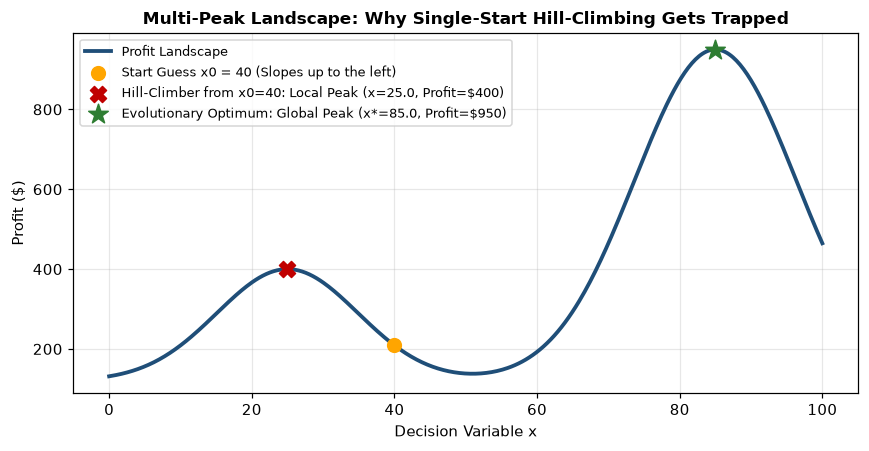

In [4]:
# Plot the Multi-Peak Landscape: Local Trap vs. Evolutionary Global Peak
x_grid = np.linspace(0, 100, 400)
y_grid = multi_peak_profit(x_grid)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x_grid, y_grid, color='#1f4e78', lw=2.5, label='Profit Landscape')
ax.scatter([40.0], [multi_peak_profit(40.0)], color='orange', s=80, zorder=5, label='Start Guess x0 = 40 (Slopes up to the left)')
ax.scatter([res_trap.x[0]], [-res_trap.fun], color='#c00000', marker='X', s=110, zorder=6,
           label=f'Hill-Climber from x0=40: Local Peak (x={res_trap.x[0]:.1f}, Profit=${-res_trap.fun:.0f})')
ax.scatter([res_evo_peak.x[0]], [-res_evo_peak.fun], color='#2e7d32', marker='*', s=180, zorder=7,
           label=f'Evolutionary Optimum: Global Peak (x*={res_evo_peak.x[0]:.1f}, Profit=${-res_evo_peak.fun:.0f})')
ax.set_title('Multi-Peak Landscape: Why Single-Start Hill-Climbing Gets Trapped', fontsize=11, fontweight='bold')
ax.set_xlabel('Decision Variable x')
ax.set_ylabel('Profit ($)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Part 4: Example 1 — Single-Variable Hoodie Order Quantity $Q$ (Slides 29–36b)
- **Downward-Sloping Demand Price:** $P(Q) = 100 - 0.5Q$
- **Total Revenue:** $R(Q) = (100 - 0.5Q) \times Q = 100Q - 0.5Q^2$
- **Wholesale Cost ($c = \$20$):** $C(Q) = 20Q$
- **Nonlinear Profit Formula:** $\Pi(Q) = 80Q - 0.5Q^2$

First, let's reproduce the **Delta Table (Slide 33)** by checking what happens when we step $+1$ unit from candidate quantities $Q = 20, 50, 79, 80, 81$.

In [5]:
def hoodie_profit(Q, cost=20.0):
    price = 100.0 - 0.5 * Q
    return price * Q - cost * Q

# Build the Slide 33 Candidate & Delta Table (No calculus!)
rows = []
for Q_test in [20, 50, 79, 80, 81, 100]:
    p_curr = 100.0 - 0.5 * Q_test
    pi_curr = hoodie_profit(Q_test)
    delta_plus_1 = hoodie_profit(Q_test + 1) - pi_curr
    rows.append({
        "Order Quantity Q": Q_test,
        "Retail Price P(Q) ($)": p_curr,
        "Total Profit Pi(Q) ($)": pi_curr,
        "Delta Profit from +1 Unit ($)": delta_plus_1
    })
display(pd.DataFrame(rows))

,Order Quantity Q,Retail Price P(Q) ($),Total Profit Pi(Q) ($),Delta Profit from +1 Unit ($)
0,20,90.0,1400.0,59.5
1,50,75.0,2750.0,29.5
2,79,60.5,3199.5,0.5
3,80,60.0,3200.0,-0.5
4,81,59.5,3199.5,-1.5
5,100,50.0,3000.0,-20.5


In [6]:
# Solve Example 1 (Slides 34-35) + Exercise (Slides 36-36b) in Python
# 1. Baseline (c = $20, bounds = [(0, 200)])
def neg_profit_baseline(x):
    Q = x[0]
    return -(80.0 * Q - 0.5 * (Q ** 2))

res_ex1_grad = minimize(neg_profit_baseline, x0=[10.0], bounds=[(0, 200)])
res_ex1_evo  = differential_evolution(neg_profit_baseline, bounds=[(0, 200)], seed=42)

# 2. Exercise Part A: Supplier Cost Shock (c = $36 -> 64*Q - 0.5*Q^2)
def neg_profit_shock(x):
    Q = x[0]
    return -(64.0 * Q - 0.5 * (Q ** 2))

res_shock_uncon = minimize(neg_profit_shock, x0=[10.0], bounds=[(0, 200)])

# 3. Exercise Part B: Supplier Cost Shock + Warehouse Cap (Q <= 50)
res_shock_cap = minimize(neg_profit_shock, x0=[10.0], bounds=[(0, 50)])

summary_ex1 = pd.DataFrame([
    {"Scenario": "Baseline (c=$20, Max Q=200) — minimize", "Optimal Q*": res_ex1_grad.x[0], "Max Profit ($)": -res_ex1_grad.fun},
    {"Scenario": "Baseline (c=$20, Max Q=200) — differential_evolution", "Optimal Q*": res_ex1_evo.x[0], "Max Profit ($)": -res_ex1_evo.fun},
    {"Scenario": "Exercise Part A: Cost Shock (c=$36, Unconstrained)", "Optimal Q*": res_shock_uncon.x[0], "Max Profit ($)": -res_shock_uncon.fun},
    {"Scenario": "Exercise Part B: Cost Shock (c=$36, Capped Q<=50)", "Optimal Q*": res_shock_cap.x[0], "Max Profit ($)": -res_shock_cap.fun},
])
display(summary_ex1.round(2))

,Scenario,Optimal Q*,Max Profit ($)
0,"Baseline (c=$20, Max Q=200) — minimize",80.0,3200.0
1,"Baseline (c=$20, Max Q=200) — differential_evo...",80.0,3200.0
2,"Exercise Part A: Cost Shock (c=$36, Unconstrai...",64.0,2048.0
3,"Exercise Part B: Cost Shock (c=$36, Capped Q<=50)",50.0,1950.0


---
## Part 5: Example 2 (Case Study Basis) — 3-Stock Markowitz Portfolio Optimization (Slides 37–49)
We allocate continuous weights `w = [w1, w2, w3]` across **Stock 1 (Tech, 14%)**, **Stock 2 (Healthcare, 10%)**, and **Stock 3 (Utilities, 6%)** using our clean 4-Step `scipy.optimize` setup:
- No `lambda` functions or matrix algebra needed: we simply unpack `w1, w2, w3 = w` inside `def portfolio_variance(w):` and use `LinearConstraint`!

In [7]:
# Step 1: Already imported minimize, differential_evolution, LinearConstraint

# Step 2: Define the 3-Stock Portfolio Variance function (We want to MINIMIZE risk, so no minus sign!)
def portfolio_variance(w):
    w1, w2, w3 = w
    own_var = 0.040 * (w1 ** 2) + 0.020 * (w2 ** 2) + 0.010 * (w3 ** 2)
    cov_terms = (
        2 * 0.003 * w1 * w2
        + 2 * (-0.005) * w1 * w3
        + 2 * 0.002 * w2 * w3
    )
    return own_var + cov_terms

# Step 3: Set Bounds (0 to 1 for each stock) and LinearConstraints
bounds_3 = [(0, 1), (0, 1), (0, 1)]

# Rule 1: 1*w1 + 1*w2 + 1*w3 = 1.0 (100% of budget invested)
budget_con = LinearConstraint([1.0, 1.0, 1.0], 1.0, 1.0)

# Rule 2: 0.14*w1 + 0.10*w2 + 0.06*w3 >= 0.10 (Target return at least 10%)
return_con = LinearConstraint([0.14, 0.10, 0.06], 0.10, float('inf'))

cons_list = [budget_con, return_con]

# Step 4A: Solve with Hill-Climbing (minimize)
res_port_grad = minimize(
    portfolio_variance, x0=[1/3, 1/3, 1/3], bounds=bounds_3, constraints=cons_list, tol=1e-9
)

# Step 4B: Solve with Evolutionary Search (differential_evolution)
res_port_evo = differential_evolution(
    portfolio_variance, bounds=bounds_3, constraints=cons_list, seed=42, tol=1e-9, polish=False
)

# Slide 48 Exercise Check: Candidate 50/50 Portfolio [0.50, 0.00, 0.50]
cand_w = [0.50, 0.00, 0.50]
cand_var = portfolio_variance(cand_w)

df_port = pd.DataFrame([
    {
        "Portfolio": "Slide 48 Candidate (50% Tech, 0% Health, 50% Util)",
        "w1 (Tech)": cand_w[0], "w2 (Health)": cand_w[1], "w3 (Util)": cand_w[2],
        "Variance": cand_var, "Std Dev Risk (%)": (cand_var ** 0.5) * 100
    },
    {
        "Portfolio": "Optimal — Hill-Climbing (minimize)",
        "w1 (Tech)": res_port_grad.x[0], "w2 (Health)": res_port_grad.x[1], "w3 (Util)": res_port_grad.x[2],
        "Variance": res_port_grad.fun, "Std Dev Risk (%)": (res_port_grad.fun ** 0.5) * 100
    },
    {
        "Portfolio": "Optimal — Evolutionary (differential_evolution)",
        "w1 (Tech)": res_port_evo.x[0], "w2 (Health)": res_port_evo.x[1], "w3 (Util)": res_port_evo.x[2],
        "Variance": res_port_evo.fun, "Std Dev Risk (%)": (res_port_evo.fun ** 0.5) * 100
    }
])
display(df_port.round(5))

,Portfolio,w1 (Tech),w2 (Health),w3 (Util),Variance,Std Dev Risk (%)
0,"Slide 48 Candidate (50% Tech, 0% Health, 50% U...",0.50,0.0,0.50,0.01000,10.00000
1,Optimal — Hill-Climbing (minimize),0.35,0.3,0.35,0.00775,8.80341
2,Optimal — Evolutionary (differential_evolution),0.35,0.3,0.35,0.00775,8.80341


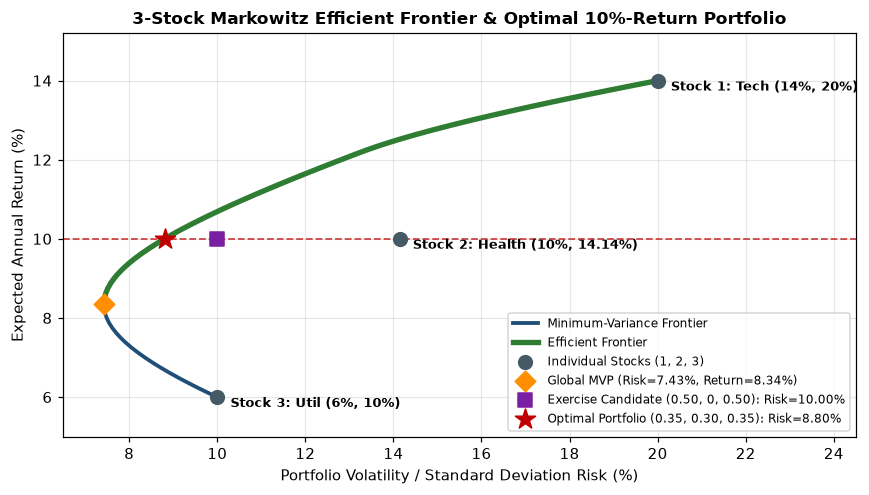

In [8]:
# Trace the 3-Stock Markowitz Efficient Frontier by Looping Over Target Returns (Slide 47)
target_returns = np.linspace(0.06, 0.14, 65)
frontier_sd = []
frontier_ret = []

for r_target in target_returns:
    ret_exact = LinearConstraint([0.14, 0.10, 0.06], r_target, r_target)
    sol = minimize(portfolio_variance, x0=[1/3, 1/3, 1/3], bounds=bounds_3,
                   constraints=[budget_con, ret_exact], tol=1e-9)
    if sol.success:
        frontier_sd.append((sol.fun ** 0.5) * 100)
        frontier_ret.append(r_target * 100)

# Find Global Minimum Variance Portfolio (MVP — no return constraint)
res_mvp = minimize(portfolio_variance, x0=[1/3, 1/3, 1/3], bounds=bounds_3, constraints=[budget_con], tol=1e-9)
mvp_sd = (res_mvp.fun ** 0.5) * 100
mvp_ret = (0.14 * res_mvp.x[0] + 0.10 * res_mvp.x[1] + 0.06 * res_mvp.x[2]) * 100

fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.plot(frontier_sd, frontier_ret, color='#1f4e78', lw=2.5, label='Minimum-Variance Frontier')

eff_mask = np.array(frontier_ret) >= mvp_ret - 1e-6
ax.plot(np.array(frontier_sd)[eff_mask], np.array(frontier_ret)[eff_mask], color='#2e7d32', lw=3.5, label='Efficient Frontier')

indiv_sd = [20.0, (0.02 ** 0.5) * 100, 10.0]
indiv_ret = [14.0, 10.0, 6.0]
ax.scatter(indiv_sd, indiv_ret, color='#455a64', s=80, zorder=5, label='Individual Stocks (1, 2, 3)')
for i, txt in enumerate(['Stock 1: Tech (14%, 20%)', 'Stock 2: Health (10%, 14.14%)', 'Stock 3: Util (6%, 10%)']):
    ax.annotate(txt, (indiv_sd[i] + 0.3, indiv_ret[i] - 0.25), fontsize=8.5, fontweight='bold')

ax.scatter([mvp_sd], [mvp_ret], color='#ff8f00', marker='D', s=90, zorder=6,
           label=f'Global MVP (Risk={mvp_sd:.2f}%, Return={mvp_ret:.2f}%)')
ax.scatter([10.0], [10.0], color='#7b1fa2', marker='s', s=85, zorder=6,
           label='Exercise Candidate (0.50, 0, 0.50): Risk=10.00%')
opt_sd = (res_port_grad.fun ** 0.5) * 100
ax.scatter([opt_sd], [10.0], color='#c00000', marker='*', s=190, zorder=7,
           label=f'Optimal Portfolio (0.35, 0.30, 0.35): Risk={opt_sd:.2f}%')
ax.axhline(10.0, color='#c00000', ls='--', lw=1.2, alpha=0.7)

ax.set_title('3-Stock Markowitz Efficient Frontier & Optimal 10%-Return Portfolio', fontsize=11, fontweight='bold')
ax.set_xlabel('Portfolio Volatility / Standard Deviation Risk (%)')
ax.set_ylabel('Expected Annual Return (%)')
ax.set_xlim(6.5, 24.5)
ax.set_ylim(5.0, 15.2)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

---
## Part 6: Bonus Additional Undergraduate NLP Examples
1. **Bonus Example A — Economic Order Quantity (EOQ) Inventory Cost Minimization ($1/Q$ curve):**
   $$\min_{Q \ge 10} \; TC(Q) = \frac{1,800,000}{Q} + 2Q$$
2. **Bonus Example B — Multi-Channel Marketing Allocation with Diminishing Returns ($\sqrt{x_i}$):**
   $$\max_{x_1, x_2, x_3 \ge 0} \; 40\sqrt{x_1} + 30\sqrt{x_2} + 20\sqrt{x_3} \quad \text{s.t.} \quad x_1 + x_2 + x_3 \le 100$$

In [9]:
# Bonus Example A: EOQ Total Cost Minimization
def eoq_cost(x):
    Q = x[0]
    return (1_800_000.0 / Q) + 2.0 * Q

res_eoq_grad = minimize(eoq_cost, x0=[500.0], bounds=[(10, 5000)])
res_eoq_evo  = differential_evolution(eoq_cost, bounds=[(10, 5000)], seed=42)
print(f"[Bonus A — EOQ] minimize Q* = {res_eoq_grad.x[0]:.2f}, diff_evolution Q* = {res_eoq_evo.x[0]:.2f}, Min Cost = ${res_eoq_grad.fun:,.2f}")

# Bonus Example B: Marketing Budget Allocation with Diminishing Returns
def neg_conversions(x):
    x1, x2, x3 = x
    return -(40.0 * (x1 ** 0.5) + 30.0 * (x2 ** 0.5) + 20.0 * (x3 ** 0.5))

ad_budget_con = LinearConstraint([1.0, 1.0, 1.0], 0.0, 100.0)
bnds_mkt = [(0, 100), (0, 100), (0, 100)]

res_mkt_grad = minimize(neg_conversions, x0=[30.0, 30.0, 30.0], bounds=bnds_mkt, constraints=[ad_budget_con], tol=1e-9)
res_mkt_evo  = differential_evolution(neg_conversions, bounds=bnds_mkt, constraints=[ad_budget_con], seed=42, tol=1e-8, polish=False)
print(f"[Bonus B — Marketing (minimize)]       Search=${res_mkt_grad.x[0]:.2f}k, Social=${res_mkt_grad.x[1]:.2f}k, Video=${res_mkt_grad.x[2]:.2f}k -> Conversions = {-res_mkt_grad.fun:.2f}")
print(f"[Bonus B — Marketing (diff_evolution)] Search=${res_mkt_evo.x[0]:.2f}k, Social=${res_mkt_evo.x[1]:.2f}k, Video=${res_mkt_evo.x[2]:.2f}k -> Conversions = {-res_mkt_evo.fun:.2f}")

[Bonus A — EOQ] minimize Q* = 948.69, diff_evolution Q* = 948.68, Min Cost = $3,794.73
[Bonus B — Marketing (minimize)]       Search=$55.17k, Social=$31.03k, Video=$13.79k -> Conversions = 538.52
[Bonus B — Marketing (diff_evolution)] Search=$55.18k, Social=$31.03k, Video=$13.79k -> Conversions = 538.52


### Q&A
- **How do we solve Nonlinear Programming (NLP) problems in Python without Excel Solver or calculus?** We use Python's pre-installed `scipy.optimize` library in Google Colab via a 4-step workflow: (1) import `minimize`, `differential_evolution`, and `LinearConstraint`; (2) define a regular Python function `def` for the objective (returning `-profit` if maximizing); (3) specify variable `bounds` and `LinearConstraint` rules; and (4) call `minimize` (Hill-Climbing) or `differential_evolution` (Evolutionary Search).
- **When does `differential_evolution` outperform `minimize`?** On smooth single-hill or single-bowl models (Examples 1 and 2), both algorithms find the exact same global optimum, whereas on multi-peak landscapes (Part 2), single-start `minimize` from `x0 = [40]` gets trapped at the local peak ($x = 25, \text{Profit} = \$400$) while `differential_evolution` finds the global peak ($x^* = 85, \text{Profit} = \$950$).

### Data Analysis Key Findings
- **Warm-Up Model (Part 1):** Evaluating candidate points $x = 9, 10, 11$ shows $\Pi(9) = \$198$, $\Pi(10) = \$200$, and $\Pi(11) = \$198$, matching Python's exact interior peak $x^* = 10.00$ ($\Pi^* = \$200.00$).
- **Example 1 — Hoodie Order Quantity $Q$ (Part 4):** Stepping $+1$ unit shows positive profit deltas up to $Q = 79$ ($+\$0.50$) and negative profit deltas starting at $Q = 80$ ($-\$0.50$), confirming the optimal order quantity $Q^* = 80.00$ hoodies ($P^* = \$60.00, \Pi^* = \$3,200.00$). When unit cost rises to $\$36$, the unconstrained peak shifts to $Q^* = 64.00$ ($\Pi^* = \$2,048.00$), and a warehouse cap of $Q \le 50$ stops the solver at the boundary $Q^* = 50.00$ ($\Pi^* = \$1,950.00$).
- **Example 2 — 3-Stock Markowitz Portfolio Case Study (Part 5):** For a $10\%$ target return, the equal Tech/Utility split $(0.50, 0.00, 0.50)$ yields variance $\sigma_p^2 = 0.01000$ ($\sigma_p = 10.00\%$), whereas both `minimize` and `differential_evolution` find the optimal 3-stock portfolio $(w_1^*, w_2^*, w_3^*) = (0.35, 0.30, 0.35)$ with minimum variance $\sigma_p^{2*} = 0.00775$ and volatility $\sigma_p^* = 8.80\%$.

### Insights or Next Steps
- **Case Study Readiness:** Students can copy the Part 5 four-step code block (`portfolio_variance` + `LinearConstraint` + `minimize` / `differential_evolution`) directly into Google Colab to solve their 3-stock portfolio case study.
- **Exploring Policy Constraints:** Try tightening `bounds_3` (for example, `[(0, 0.30)] * 3` so no single stock exceeds $30\%$ of the fund) and re-running the cell to observe how concentration limits shift the optimal weights.